# 03 — Klasifikasi Teks: BiLSTM vs IndoBERT

**Proyek:** Analisis Dinamika Topik Pemberitaan Generative AI pada Media Online Indonesia Menggunakan BERTopic

**Video penjelasan:** `<<TEMPEL LINK VIDEO DI SINI>>`

Notebook ini menjawab Task 3: membangun dua model klasifikasi domain berita (5 kelas) —
satu model *deep learning* (BiLSTM) dan satu model berbasis BERT (IndoBERT) — masing-masing dengan
*hyperparameter tuning* minimal 2 hyperparameter, lalu membandingkan dan menganalisis hasilnya.
Model terbaik dipakai untuk menetapkan kelas akhir setiap dokumen, yang menjadi masukan
*topic modelling* per kelas di notebook 04.

In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
import itertools, json, random, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

ROOT = Path.cwd()   # jalankan notebook dari folder repo
SCRAPED, RES, MODELS, FIG = ROOT / "scraped", ROOT / "results", ROOT / "models", ROOT / "figures"
for _d in (SCRAPED, RES, MODELS, FIG):
    _d.mkdir(exist_ok=True)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")


def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU


## 1. Data dan pembagian train / validation / test

Label kelas adalah **domain berita** yang ditetapkan redaksi (kanal tempat artikel terbit), sehingga
label tidak dibuat oleh model lain. Nama media dan nama kanal sudah dibuang dari teks pada tahap
preprocessing supaya label tidak "bocor" ke fitur. Data dibagi **80% / 10% / 10%** secara
*stratified* agar proporsi kelas sama di ketiga bagian. Validation dipakai untuk memilih
hyperparameter dan *early stopping*; test hanya disentuh sekali untuk evaluasi akhir.

In [2]:
df = pd.read_csv(ROOT / "dataset_clean.csv", parse_dates=["date"])
df["desc"] = df["desc"].fillna("")
LABELS = sorted(df["label"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
df["y"] = df["label"].map(label2id)
df["text"] = df["title"] + ". " + df["body_clean"].str.replace("\n", " ")

train_df, tmp = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp["y"], random_state=SEED)
split = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
split[["doc_id", "split"]].to_csv(RES / "split.csv", index=False)
pd.crosstab(split["label"], split["split"])[["train", "val", "test"]]

split,train,val,test
label,,,
Ekonomi,783,98,98
Hiburan,598,74,75
Nasional,1019,127,128
Pendidikan,571,72,71
Teknologi,2400,300,300


In [3]:
def evaluate_preds(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": p, "recall_macro": r, "f1_macro": f}


# bobot kelas (inverse frequency) untuk menangani ketidakseimbangan kelas di fungsi loss
counts = np.bincount(train_df["y"], minlength=len(LABELS))
class_weights = torch.tensor(len(train_df) / (len(LABELS) * counts), dtype=torch.float, device=DEVICE)
dict(zip(LABELS, class_weights.cpu().numpy().round(2)))

{'Ekonomi': np.float32(1.37),
 'Hiburan': np.float32(1.8),
 'Nasional': np.float32(1.05),
 'Pendidikan': np.float32(1.88),
 'Teknologi': np.float32(0.45)}

**Metrik.** Karena jumlah dokumen per kelas tidak sama, metrik utama adalah **macro-F1**: rata-rata F1
tiap kelas dengan bobot sama, sehingga kelas kecil tidak tertutup oleh kelas besar. Accuracy,
macro-precision, dan macro-recall dilaporkan sebagai pelengkap.

## 2. Model 1 — BiLSTM

**Representasi teks.** Teks di-*case-fold*, angka/tanda baca dibuang, stopword dihapus, lalu tiap token
dipetakan ke indeks kosakata (kosakata dibangun **hanya dari data train**; kata dengan frekuensi < 2
menjadi `<unk>`). Urutan dipotong/di-*pad* ke 300 token. Embedding (200 dimensi) dilatih dari nol
bersama model.

**Arsitektur.** Embedding → BiLSTM → gabungan *max-pooling* dan *mean-pooling* atas seluruh langkah
waktu → dropout → lapisan linear. BiLSTM dipilih karena membaca urutan dari dua arah; pooling atas
semua langkah lebih stabil untuk dokumen panjang dibanding hanya mengambil *hidden state* terakhir.

In [4]:
MAX_LEN_LSTM, MIN_FREQ, MAX_VOCAB = 300, 2, 30000
tok_train = [t.split() for t in train_df["tokens"]]
freq = pd.Series([w for d in tok_train for w in d]).value_counts()
vocab = ["<pad>", "<unk>"] + freq[freq >= MIN_FREQ].index[:MAX_VOCAB].tolist()
w2i = {w: i for i, w in enumerate(vocab)}
print("ukuran kosakata:", len(vocab), "| median panjang token:", int(np.median([len(d) for d in tok_train])))


def encode(token_strings):
    X = np.zeros((len(token_strings), MAX_LEN_LSTM), dtype=np.int64)
    for i, t in enumerate(token_strings):
        ids = [w2i.get(w, 1) for w in t.split()][:MAX_LEN_LSTM]
        X[i, :len(ids)] = ids
    return torch.tensor(X)


Xtr, Xva, Xte = encode(train_df["tokens"]), encode(val_df["tokens"]), encode(test_df["tokens"])
ytr, yva, yte = (torch.tensor(d["y"].values) for d in (train_df, val_df, test_df))


class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, emb_dim=200, hidden=128, dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 4, n_classes)

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        out, _ = self.lstm(self.drop(self.emb(x)))
        mx = out.masked_fill(~mask, -1e9).max(1).values
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(self.drop(torch.cat([mx, mean], 1)))


@torch.no_grad()
def predict_lstm(model, X, bs=256):
    model.eval()
    return torch.cat([model(X[i:i + bs].to(DEVICE)).argmax(1).cpu() for i in range(0, len(X), bs)]).numpy()


def train_lstm(hidden, lr, dropout, max_epochs=12, patience=3, bs=64):
    set_seed()
    model = BiLSTMClassifier(len(vocab), len(LABELS), hidden=hidden, dropout=dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss(weight=class_weights)
    best, best_state, hist, bad = -1, None, [], 0
    for ep in range(1, max_epochs + 1):
        model.train()
        perm, tot = torch.randperm(len(Xtr)), 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = lossf(model(Xtr[idx].to(DEVICE)), ytr[idx].to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(idx)
        f1 = evaluate_preds(yva.numpy(), predict_lstm(model, Xva))["f1_macro"]
        hist.append({"epoch": ep, "train_loss": tot / len(Xtr), "val_f1": f1})
        if f1 > best:
            best, bad = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best, hist

ukuran kosakata: 30002 | median panjang token: 220


### Hyperparameter tuning BiLSTM (grid search, 3 hyperparameter)

| Hyperparameter | Nilai yang dicoba | Alasan |
|---|---|---|
| `hidden` (ukuran hidden LSTM) | 64, 128 | kapasitas model |
| `lr` (learning rate Adam) | 1e-3, 5e-4 | kecepatan & kestabilan konvergensi |
| `dropout` | 0.3, 0.5 | regularisasi (embedding dilatih dari nol → mudah overfit) |

Total 8 konfigurasi; tiap konfigurasi memakai *early stopping* (patience 3) pada macro-F1 validation.

In [5]:
lstm_runs, lstm_best = [], (-1, None, None, None)
for hidden, lr, dropout in itertools.product([64, 128], [1e-3, 5e-4], [0.3, 0.5]):
    t0 = time.time()
    model, f1, hist = train_lstm(hidden, lr, dropout)
    lstm_runs.append({"hidden": hidden, "lr": lr, "dropout": dropout, "val_f1_macro": f1,
                      "best_epoch": int(np.argmax([h["val_f1"] for h in hist])) + 1,
                      "epochs_run": len(hist), "time_s": round(time.time() - t0, 1)})
    print(lstm_runs[-1])
    if f1 > lstm_best[0]:
        lstm_best = (f1, model, hist, lstm_runs[-1])
lstm_tuning = pd.DataFrame(lstm_runs).sort_values("val_f1_macro", ascending=False)
lstm_tuning.to_csv(RES / "tuning_bilstm.csv", index=False)
lstm_tuning

{'hidden': 64, 'lr': 0.001, 'dropout': 0.3, 'val_f1_macro': 0.6471275416049662, 'best_epoch': 6, 'epochs_run': 9, 'time_s': 7.6}


{'hidden': 64, 'lr': 0.001, 'dropout': 0.5, 'val_f1_macro': 0.6221946322018451, 'best_epoch': 7, 'epochs_run': 10, 'time_s': 6.2}


{'hidden': 64, 'lr': 0.0005, 'dropout': 0.3, 'val_f1_macro': 0.5885630433624311, 'best_epoch': 11, 'epochs_run': 12, 'time_s': 7.4}


{'hidden': 64, 'lr': 0.0005, 'dropout': 0.5, 'val_f1_macro': 0.4846732487361599, 'best_epoch': 4, 'epochs_run': 7, 'time_s': 4.3}


{'hidden': 128, 'lr': 0.001, 'dropout': 0.3, 'val_f1_macro': 0.6864935721163264, 'best_epoch': 10, 'epochs_run': 12, 'time_s': 14.2}


{'hidden': 128, 'lr': 0.001, 'dropout': 0.5, 'val_f1_macro': 0.6790423799214615, 'best_epoch': 6, 'epochs_run': 9, 'time_s': 10.9}


{'hidden': 128, 'lr': 0.0005, 'dropout': 0.3, 'val_f1_macro': 0.6462798753692643, 'best_epoch': 10, 'epochs_run': 12, 'time_s': 14.2}


{'hidden': 128, 'lr': 0.0005, 'dropout': 0.5, 'val_f1_macro': 0.5767950384854216, 'best_epoch': 10, 'epochs_run': 12, 'time_s': 14.3}


,hidden,lr,dropout,val_f1_macro,best_epoch,epochs_run,time_s
4,128,0.0010,0.3,0.686494,10,12,14.2
5,128,0.0010,0.5,0.679042,6,9,10.9
0,64,0.0010,0.3,0.647128,6,9,7.6
6,128,0.0005,0.3,0.646280,10,12,14.2
1,64,0.0010,0.5,0.622195,7,10,6.2
2,64,0.0005,0.3,0.588563,11,12,7.4
7,128,0.0005,0.5,0.576795,10,12,14.3
3,64,0.0005,0.5,0.484673,4,7,4.3


In [6]:
_, lstm_model, lstm_hist, lstm_cfg = lstm_best
torch.save({"state": lstm_model.state_dict(), "vocab": vocab, "cfg": lstm_cfg, "labels": LABELS}, MODELS / "bilstm_best.pt")
lstm_pred = predict_lstm(lstm_model, Xte)
lstm_test = evaluate_preds(yte.numpy(), lstm_pred)
print("Konfigurasi terbaik:", lstm_cfg)
print("Test:", {k: round(v, 4) for k, v in lstm_test.items()})
print(classification_report(yte.numpy(), lstm_pred, target_names=LABELS, digits=3))

Konfigurasi terbaik: {'hidden': 128, 'lr': 0.001, 'dropout': 0.3, 'val_f1_macro': 0.6864935721163264, 'best_epoch': 10, 'epochs_run': 12, 'time_s': 14.2}
Test: {'accuracy': 0.747, 'precision_macro': 0.7185, 'recall_macro': 0.7215, 'f1_macro': 0.7052}
              precision    recall  f1-score   support

     Ekonomi      0.589     0.745     0.658        98
     Hiburan      0.700     0.747     0.723        75
    Nasional      0.829     0.453     0.586       128
  Pendidikan      0.640     0.803     0.713        71
   Teknologi      0.835     0.860     0.847       300

    accuracy                          0.747       672
   macro avg      0.719     0.722     0.705       672
weighted avg      0.762     0.747     0.742       672



**Interpretasi tuning BiLSTM.** Konfigurasi terbaik adalah `hidden=128, lr=1e-3, dropout=0.3`
(macro-F1 validation 0,687). Polanya konsisten di semua kombinasi:

- **Hidden 128 > 64** pada semua pasangan lr/dropout: dokumen berita panjang (median ±250 token setelah
  preprocessing) butuh kapasitas lebih untuk menyimpan konteks.
- **Dropout 0,5 menurunkan skor** pada semua pasangan (hingga −0,10 pada hidden 64, lr 5e-4): embedding
  dilatih dari nol dengan ±5.400 dokumen, sehingga regularisasi terlalu kuat membuat model sulit belajar.
- **Learning rate 1e-3 lebih baik daripada 5e-4** pada semua pasangan; dengan 5e-4 beberapa konfigurasi
  baru mencapai skor terbaik di epoch 10–11 dari batas 12 epoch, artinya belajarnya terlalu lambat.

Rentang skornya lebar (0,48–0,69): BiLSTM **sensitif** terhadap hyperparameter.

## 3. Model 2 — IndoBERT (fine-tuning)

Model: **`indobenchmark/indobert-base-p2`** (BERT-base, 12 layer, ±124 juta parameter) yang
di-*pretrain* pada ±4 miliar kata teks Indonesia (Indo4B). Dipilih karena korpus kita berbahasa
Indonesia; model multibahasa (mBERT) membagi kapasitasnya ke 100+ bahasa.

**Masukan.** Teks **alami** (judul + isi, hanya dibersihkan ringan; huruf besar, tanda baca dan stopword
dipertahankan) karena BERT di-*pretrain* pada kalimat utuh dan memanfaatkan konteks kata fungsi.
Tokenisasi memakai WordPiece bawaan model. Pelatihan: AdamW, *linear warmup* 10%, *mixed precision*
(fp16), 3 epoch, checkpoint terbaik dipilih dari macro-F1 validation.

In [7]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

BERT_NAME = "indobenchmark/indobert-base-p2"
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)


class TxtDS(Dataset):
    def __init__(self, texts, labels, max_len):
        self.enc = tokenizer(list(texts), truncation=True, max_length=max_len)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i],
                "labels": self.labels[i]}


def collate(batch):
    out = tokenizer.pad([{k: b[k] for k in ("input_ids", "attention_mask")} for b in batch], return_tensors="pt")
    out["labels"] = torch.tensor([b["labels"] for b in batch])
    return out


@torch.no_grad()
def predict_bert(model, ds, bs=64):
    model.eval()
    preds = []
    for b in DataLoader(ds, batch_size=bs, collate_fn=collate):
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            preds.append(model(**b).logits.argmax(1).cpu())
    return torch.cat(preds).numpy()


def train_bert(lr, max_len, epochs=3, bs=16, save_to=None):
    set_seed()
    tr, va = TxtDS(train_df["text"], train_df["y"], max_len), TxtDS(val_df["text"], val_df["y"], max_len)
    model = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=len(LABELS)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    dl = DataLoader(tr, batch_size=bs, shuffle=True, collate_fn=collate)
    steps = len(dl) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    lossf = nn.CrossEntropyLoss(weight=class_weights)
    best, hist = -1, []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            y = b.pop("labels")
            opt.zero_grad()
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = lossf(model(**b).logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y)
        f1 = evaluate_preds(val_df["y"].values, predict_bert(model, va))["f1_macro"]
        hist.append({"epoch": ep, "train_loss": tot / len(tr), "val_f1": f1})
        if f1 > best:
            best = f1
            if save_to is not None:
                model.save_pretrained(save_to); tokenizer.save_pretrained(save_to)
    del model, opt; torch.cuda.empty_cache()
    return best, hist

### Hyperparameter tuning IndoBERT (grid search, 2 hyperparameter)

| Hyperparameter | Nilai yang dicoba | Alasan |
|---|---|---|
| `lr` (learning rate AdamW) | 2e-5, 5e-5 | rentang yang direkomendasikan paper BERT; terlalu besar merusak bobot pretrained |
| `max_len` (panjang masukan, token) | 128, 256 | berapa banyak isi artikel yang dibaca model; berita memakai struktur piramida terbalik, jadi menarik dilihat apakah bagian awal saja cukup |

Batch size 16 dan 3 epoch dibuat tetap agar perbandingan adil dan muat di GPU 8 GB.

In [8]:
bert_runs, bert_hists = [], {}
for lr, max_len in itertools.product([2e-5, 5e-5], [128, 256]):
    t0 = time.time()
    f1, hist = train_bert(lr, max_len, save_to=MODELS / f"indobert_lr{lr}_len{max_len}")
    bert_hists[(lr, max_len)] = hist
    bert_runs.append({"lr": lr, "max_len": max_len, "val_f1_macro": f1,
                      "best_epoch": int(np.argmax([h["val_f1"] for h in hist])) + 1,
                      "time_s": round(time.time() - t0, 1)})
    print(bert_runs[-1])
bert_tuning = pd.DataFrame(bert_runs).sort_values("val_f1_macro", ascending=False)
bert_tuning.to_csv(RES / "tuning_indobert.csv", index=False)
bert_tuning

{'lr': 2e-05, 'max_len': 128, 'val_f1_macro': 0.7698292487889378, 'best_epoch': 3, 'time_s': 132.4}


{'lr': 2e-05, 'max_len': 256, 'val_f1_macro': 0.7763677736590329, 'best_epoch': 3, 'time_s': 204.8}


{'lr': 5e-05, 'max_len': 128, 'val_f1_macro': 0.7788454430502869, 'best_epoch': 3, 'time_s': 132.6}


{'lr': 5e-05, 'max_len': 256, 'val_f1_macro': 0.7843585493178447, 'best_epoch': 3, 'time_s': 206.4}


,lr,max_len,val_f1_macro,best_epoch,time_s
3,0.00005,256,0.784359,3,206.4
2,0.00005,128,0.778845,3,132.6
1,0.00002,256,0.776368,3,204.8
0,0.00002,128,0.769829,3,132.4


In [9]:
import shutil

bert_cfg = bert_tuning.iloc[0].to_dict()
best_dir = MODELS / f"indobert_lr{bert_cfg['lr']}_len{int(bert_cfg['max_len'])}"
for d in MODELS.glob("indobert_lr*"):          # simpan hanya checkpoint terbaik
    if d != best_dir:
        shutil.rmtree(d)
if (MODELS / "indobert_best").exists():
    shutil.rmtree(MODELS / "indobert_best")
best_dir.rename(MODELS / "indobert_best")
bert_model = AutoModelForSequenceClassification.from_pretrained(MODELS / "indobert_best").to(DEVICE)
BEST_LEN = int(bert_cfg["max_len"])
bert_pred = predict_bert(bert_model, TxtDS(test_df["text"], test_df["y"], BEST_LEN))
bert_test = evaluate_preds(test_df["y"].values, bert_pred)
print("Konfigurasi terbaik:", bert_cfg)
print("Test:", {k: round(v, 4) for k, v in bert_test.items()})
print(classification_report(test_df["y"].values, bert_pred, target_names=LABELS, digits=3))

Konfigurasi terbaik: {'lr': 5e-05, 'max_len': 256.0, 'val_f1_macro': 0.7843585493178447, 'best_epoch': 3.0, 'time_s': 206.4}
Test: {'accuracy': 0.8304, 'precision_macro': 0.8023, 'recall_macro': 0.8189, 'f1_macro': 0.8082}
              precision    recall  f1-score   support

     Ekonomi      0.770     0.888     0.825        98
     Hiburan      0.813     0.813     0.813        75
    Nasional      0.818     0.703     0.756       128
  Pendidikan      0.716     0.817     0.763        71
   Teknologi      0.894     0.873     0.884       300

    accuracy                          0.830       672
   macro avg      0.802     0.819     0.808       672
weighted avg      0.834     0.830     0.830       672



**Interpretasi tuning IndoBERT.** Keempat konfigurasi berada di rentang yang jauh lebih sempit
(0,770–0,784) daripada BiLSTM: model pretrained lebih **stabil** karena sebagian besar pengetahuan
bahasanya sudah ada di bobot awal. Kombinasi terbaik `lr=5e-5, max_len=256`. Learning rate yang lebih
besar dan masukan yang lebih panjang sama-sama membantu (masing-masing ±+0,006–0,009), tetapi efeknya
kecil — informasi penentu domain sudah ada di bagian awal artikel (piramida terbalik). Semua konfigurasi
mencapai skor terbaik di epoch terakhir (epoch 3), sehingga epoch tambahan kemungkinan masih bisa
menaikkan skor.

## 4. Perbandingan dan evaluasi

In [10]:
n_params = lambda m: sum(p.numel() for p in m.parameters())
comparison = pd.DataFrame([
    {"model": "BiLSTM", **lstm_test, "val_f1_macro": lstm_cfg["val_f1_macro"], "parameter": n_params(lstm_model),
     "waktu_latih_s": lstm_cfg["time_s"]},
    {"model": "IndoBERT", **bert_test, "val_f1_macro": bert_cfg["val_f1_macro"], "parameter": n_params(bert_model),
     "waktu_latih_s": bert_cfg["time_s"]},
]).set_index("model")
comparison.to_csv(RES / "classification_comparison.csv")
comparison.round(4)

,accuracy,precision_macro,recall_macro,f1_macro,val_f1_macro,parameter,waktu_latih_s
model,,,,,,,
BiLSTM,0.7470,0.7185,0.7215,0.7052,0.6865,6340885,14.2
IndoBERT,0.8304,0.8023,0.8189,0.8082,0.7844,124445189,206.4


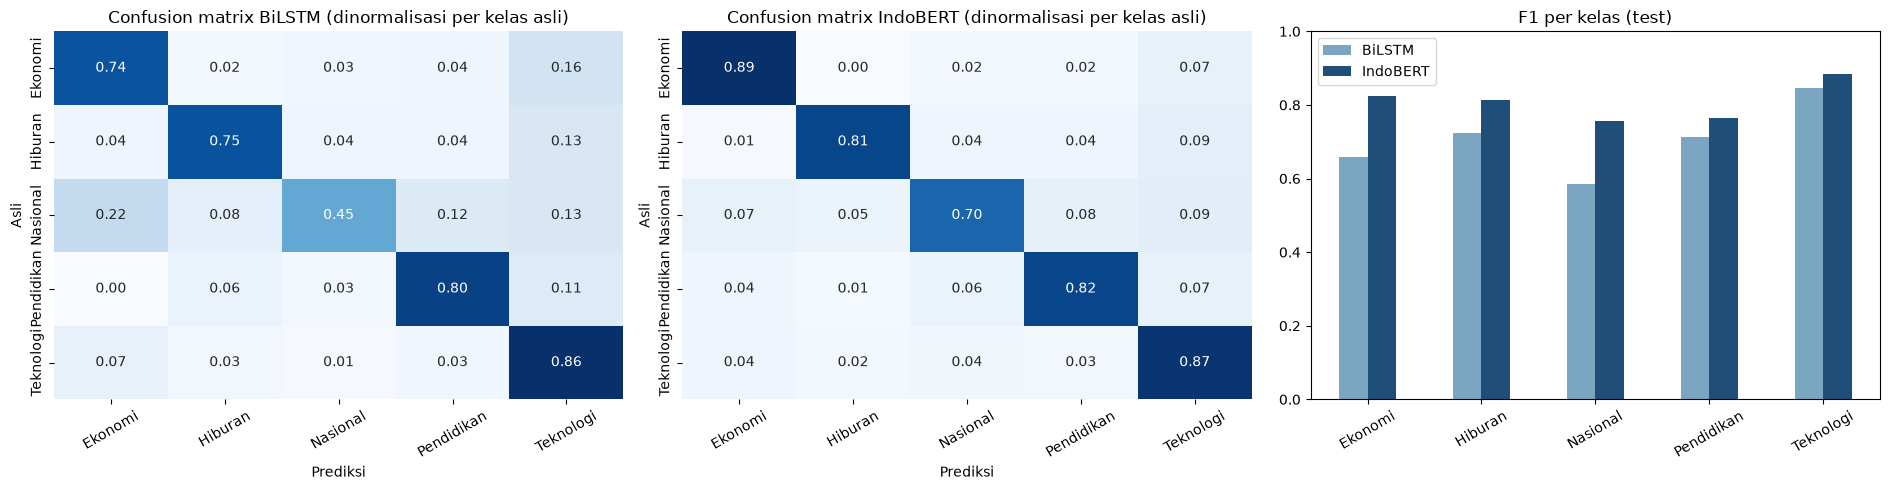

,BiLSTM,IndoBERT,selisih
Ekonomi,0.658,0.825,0.167
Hiburan,0.723,0.813,0.091
Nasional,0.586,0.756,0.170
Pendidikan,0.712,0.763,0.051
Teknologi,0.847,0.884,0.036


In [11]:
per_class = pd.DataFrame({
    "BiLSTM": precision_recall_fscore_support(yte.numpy(), lstm_pred, zero_division=0)[2],
    "IndoBERT": precision_recall_fscore_support(yte.numpy(), bert_pred, zero_division=0)[2],
}, index=LABELS)
per_class["selisih"] = per_class["IndoBERT"] - per_class["BiLSTM"]
per_class.to_csv(RES / "classification_f1_per_class.csv")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, pred, name in [(ax[0], lstm_pred, "BiLSTM"), (ax[1], bert_pred, "IndoBERT")]:
    cm = confusion_matrix(yte.numpy(), pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=a, cbar=False)
    a.set_title(f"Confusion matrix {name} (dinormalisasi per kelas asli)"); a.set_xlabel("Prediksi"); a.set_ylabel("Asli")
    a.tick_params(axis="x", rotation=30)
per_class[["BiLSTM", "IndoBERT"]].plot.bar(ax=ax[2], color=["#7aa6c2", "#1f4e79"])
ax[2].set_title("F1 per kelas (test)"); ax[2].set_ylim(0, 1); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "03_confusion_f1.png", dpi=150); plt.show()
per_class.round(3)

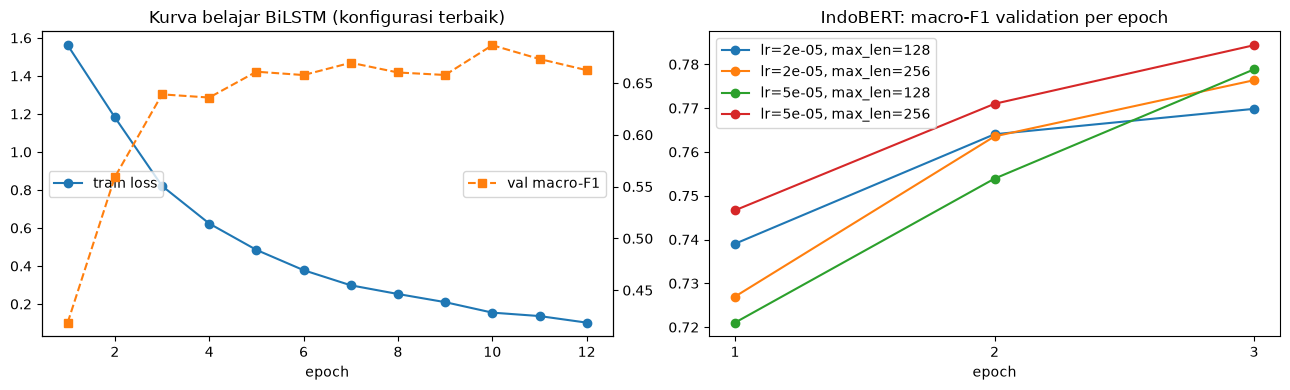

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot([h["epoch"] for h in lstm_hist], [h["train_loss"] for h in lstm_hist], "o-", label="train loss")
a2 = ax[0].twinx(); a2.plot([h["epoch"] for h in lstm_hist], [h["val_f1"] for h in lstm_hist], "s--", color="C1", label="val macro-F1")
ax[0].set_title("Kurva belajar BiLSTM (konfigurasi terbaik)"); ax[0].set_xlabel("epoch"); ax[0].legend(loc="center left"); a2.legend(loc="center right")
for (lr, ml), hist in bert_hists.items():
    ax[1].plot([h["epoch"] for h in hist], [h["val_f1"] for h in hist], "o-", label=f"lr={lr}, max_len={ml}")
ax[1].set_title("IndoBERT: macro-F1 validation per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_xticks([1, 2, 3]); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "03_learning_curves.png", dpi=150); plt.show()

**Interpretasi perbandingan.** IndoBERT unggul jelas: macro-F1 test **0,808 vs 0,705** (+0,103) dan
accuracy **0,830 vs 0,747**, dan unggul di **kelima** kelas (selisih F1 +0,04 sampai +0,17).

Mengapa IndoBERT lebih baik?

1. **Pengetahuan bahasa dari pretraining.** IndoBERT sudah membaca ±4 miliar kata teks Indonesia,
   sedangkan BiLSTM belajar embedding dari nol dengan ±5.400 dokumen — terlalu sedikit untuk mempelajari
   makna ±30 ribu kata.
2. **Konteks dua arah penuh (self-attention).** Domain berita sering ditentukan oleh *siapa* dan *dalam
   peran apa* ("Menteri X", "Polda Y", "dosen UGM"), bukan oleh satu kata. Attention dapat menghubungkan
   kata yang berjauhan; BiLSTM merangkum urutan panjang ke vektor berukuran tetap.
3. **Tidak ada informasi yang dibuang.** BiLSTM memakai token tanpa stopword/tanda baca; IndoBERT membaca
   kalimat utuh termasuk gaya bahasa khas tiap rubrik.

Kelemahan BiLSTM paling jelas di **Nasional** (recall hanya 0,45, precision 0,83): model enggan menebak
Nasional dan melempar artikelnya ke kelas lain, karena berita Nasional tentang AI sangat beragam
(kriminal, kebijakan, pidato pejabat) sehingga tidak punya kata kunci tunggal. IndoBERT menaikkan F1
Nasional dan Ekonomi paling besar (+0,17). Kelas tersulit bagi IndoBERT tetap **Nasional** (F1 0,76) dan
**Pendidikan** (0,76), dua kelas yang paling sering beririsan dengan berita kebijakan dan teknologi.

**Biaya.** IndoBERT 20× lebih besar (124 juta vs 6,3 juta parameter) dan ±15× lebih lama dilatih (±3,5
menit vs ±14 detik per konfigurasi di RTX 4070). Untuk tugas ini selisih +0,10 macro-F1 sepadan, sehingga
IndoBERT dipilih sebagai model akhir.

## 5. Analisis kesalahan

Contoh dokumen test yang diprediksi **benar** oleh kedua model, yang hanya benar oleh IndoBERT, dan yang
**salah** oleh keduanya. Tujuannya memahami *mengapa* model keliru, bukan sekadar berapa kali.

In [13]:
err = test_df[["doc_id", "source", "title", "label"]].copy()
err["bilstm"] = [LABELS[i] for i in lstm_pred]
err["indobert"] = [LABELS[i] for i in bert_pred]
err.to_csv(RES / "test_predictions.csv", index=False)
both_ok = err[(err.bilstm == err.label) & (err.indobert == err.label)]
bert_only = err[(err.bilstm != err.label) & (err.indobert == err.label)]
lstm_only = err[(err.bilstm == err.label) & (err.indobert != err.label)]
both_wrong = err[(err.bilstm != err.label) & (err.indobert != err.label)]
print(f"keduanya benar: {len(both_ok)} | hanya IndoBERT benar: {len(bert_only)} | "
      f"hanya BiLSTM benar: {len(lstm_only)} | keduanya salah: {len(both_wrong)}  (n test = {len(err)})")
pd.set_option("display.max_colwidth", 110)
display(both_ok.sample(4, random_state=1)[["title", "label", "bilstm", "indobert"]])
display(bert_only.sample(min(6, len(bert_only)), random_state=1)[["title", "label", "bilstm", "indobert"]])
display(both_wrong.sample(min(8, len(both_wrong)), random_state=1)[["title", "label", "bilstm", "indobert"]])

keduanya benar: 461 | hanya IndoBERT benar: 97 | hanya BiLSTM benar: 41 | keduanya salah: 73  (n test = 672)


,title,label,bilstm,indobert
6603,Top 3 Tekno: AS Blokir DeepSeek Jadi Sorotan,Teknologi,Teknologi,Teknologi
4229,"WhatsApp Larang Chatbot Pihak Ketiga dari Microsoft dan OpenAI, Ini Alasannya",Teknologi,Teknologi,Teknologi
1856,"OpenAI Tantang Google dengan ChatGPT Search, Mesin Pencari Baru Berbasis AI",Teknologi,Teknologi,Teknologi
6082,"Astra Model OpenAI Super Edan, Dengan Mudah Masuk ke Sistem Komputer",Teknologi,Teknologi,Teknologi


,title,label,bilstm,indobert
6389,"Pusat Data AI Jatiluhur Disetop Sementara, Dedi Mulyadi: Tak Ada Peresmian",Nasional,Ekonomi,Nasional
1973,Kecerdasan Buatan di Industri Musik: Ancaman atau Anugerah bagi Musisi?,Pendidikan,Hiburan,Pendidikan
5012,Cerita Prabowo Jadi Korban Hoaks AI: Ada Pidato Saya Bahasa Mandarin-Arab,Nasional,Ekonomi,Nasional
5514,A24 Dapat Suntikan Investasi Google Kembangkan AI,Hiburan,Teknologi,Hiburan
2082,"Sudah Bisa di X, Begini Cara Membuat Gambar dengan Grok AI",Teknologi,Nasional,Teknologi
506,"Lampu Merah Dipasang Teknologi AI, Jadi Bisa Apa Aja?",Ekonomi,Nasional,Ekonomi


,title,label,bilstm,indobert
5086,Skandal AI Terbesar: iLearning Engines Diduga Tipu Investor Rp 25 Triliun,Nasional,Teknologi,Teknologi
5125,"Peneliti MIT Ajarkan AI Berani Bilang ""Nggak Tahu"" Biar Nggak Halu",Pendidikan,Teknologi,Teknologi
2392,"Jack Ma Damai dengan Xi Jinping, Alibaba Gaspol",Teknologi,Ekonomi,Ekonomi
5538,Contoh Pengenalan Pola dalam Teknologi dan Kehidupan Sehari-hari yang Perlu Dipahami,Hiburan,Teknologi,Pendidikan
6316,"Raksasa AI Ekspansi Besar-besaran di Singapura, Sewa Kantor Meroket",Teknologi,Ekonomi,Ekonomi
4692,"Misteri Hilangnya Wahana Soviet Pertama di Bulan Terungkap, Dilacak Pakai AI",Pendidikan,Teknologi,Teknologi
867,"Gemini Dirilis, AI Milik Google Diklaim Jadi Saingan Kuat ChatGPT",Nasional,Teknologi,Teknologi
606,"Marak Pornografi Pakai AI, Aturan Konten Seksual Diperketat",Teknologi,Ekonomi,Nasional


In [14]:
# pasangan kelas yang paling sering tertukar (IndoBERT)
cm = pd.DataFrame(confusion_matrix(test_df["y"].values, bert_pred), index=LABELS, columns=LABELS)
conf = cm.where(~np.eye(len(LABELS), dtype=bool)).stack().sort_values(ascending=False).head(6)
conf.rename("jumlah").rename_axis(["asli", "prediksi"]).reset_index()

,asli,prediksi,jumlah
0,Teknologi,Ekonomi,13.0
1,Nasional,Teknologi,12.0
2,Teknologi,Nasional,11.0
3,Nasional,Pendidikan,10.0
4,Nasional,Ekonomi,9.0
5,Teknologi,Pendidikan,8.0


**Interpretasi analisis kesalahan.** Dari 672 dokumen test: 461 benar oleh keduanya, 97 hanya benar oleh
IndoBERT, 41 hanya benar oleh BiLSTM, dan 73 salah oleh keduanya.

- **Yang hanya benar oleh IndoBERT** umumnya artikel yang kosakatanya menyesatkan bagi model berbasis kata:
  "Pusat Data AI Jatiluhur Disetop Sementara, Dedi Mulyadi: Tak Ada Peresmian" dan "Cerita Prabowo Jadi
  Korban Hoaks AI" (Nasional, tetapi memuat kata investasi/proyek sehingga BiLSTM menebak Ekonomi), atau
  "A24 Dapat Suntikan Investasi Google Kembangkan AI" (Hiburan — A24 adalah studio film — ditebak
  Teknologi oleh BiLSTM).
- **Yang salah oleh keduanya** sebagian besar **ambiguitas label**, bukan kesalahan model: "Jack Ma Damai
  dengan Xi Jinping, Alibaba Gaspol" dan "Raksasa AI Ekspansi di Singapura, Sewa Kantor Meroket"
  diterbitkan di kanal Teknologi padahal isinya bisnis; "Gemini Dirilis, AI Milik Google Diklaim Jadi
  Saingan Kuat ChatGPT" diterbitkan di kanal Nasional padahal isinya peluncuran produk teknologi. Label
  kami adalah kanal penerbit, dan redaksi kadang menaruh berita serupa di kanal berbeda.
- Pasangan yang paling sering tertukar pada IndoBERT: Teknologi→Ekonomi (13), Nasional→Teknologi (12),
  Teknologi→Nasional (11) — semuanya pasangan yang memang tumpang tindih di berita AI (bisnis perusahaan
  teknologi, kebijakan AI pemerintah).

Artinya skor ±0,81–0,83 kemungkinan dekat dengan batas atas yang realistis untuk label kanal.

## 6. Klasifikasi akhir seluruh korpus

Model terbaik dipakai untuk menetapkan kelas tiap dokumen (*final classification*). Kolom `pred_label`
inilah yang dipakai untuk memisahkan korpus menjadi lima sub-korpus pada tahap *topic modelling* per
kelas (notebook 04), sesuai alur pipeline pada soal.

In [15]:
best_name = comparison["f1_macro"].idxmax()
if best_name == "IndoBERT":
    all_pred = predict_bert(bert_model, TxtDS(df["text"], df["y"], BEST_LEN))
else:
    all_pred = predict_lstm(lstm_model, encode(df["tokens"]))
out = df.drop(columns=["text", "y"]).copy()
out["pred_label"] = [LABELS[i] for i in all_pred]
out = out.merge(split[["doc_id", "split"]], on="doc_id")
out.to_csv(ROOT / "dataset_classified.csv", index=False, encoding="utf-8-sig")
print("Model akhir:", best_name)
print("Kesesuaian pred_label dengan label redaksi per split:")
print(out.assign(ok=out.label == out.pred_label).groupby("split")["ok"].mean().round(4))
out["pred_label"].value_counts()

Model akhir: IndoBERT
Kesesuaian pred_label dengan label redaksi per split:
split
test     0.8304
train    0.9473
val      0.8063
Name: ok, dtype: float64


pred_label
Teknologi     2864
Nasional      1268
Ekonomi       1079
Hiburan        766
Pendidikan     737
Name: count, dtype: int64

**Catatan klasifikasi akhir.** IndoBERT dipakai untuk memberi kelas pada seluruh 6.714 dokumen.
Kesesuaian dengan label redaksi: 0,95 di train, 0,81 di validation, 0,83 di test. Pada tahap topic
modelling, korpus dipisah menurut **kelas prediksi** ini (bukan label redaksi), sesuai alur pipeline pada
soal: *Final Classification → Class A/B/C → Topic Model*.